In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier

from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('/content/customer_churn_data.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST0000,Male,0,No,Yes,23,No,No phone service,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer,49.85,1146.55,No
1,CUST0001,Female,0,Yes,No,43,No,No phone service,DSL,Yes,...,Yes,No,Yes,No,Month-to-month,No,Mailed check,100.70,4330.10,Yes
2,CUST0002,Male,1,No,No,51,Yes,No,DSL,No,...,Yes,Yes,No,No,One year,No,Electronic check,97.33,4963.83,Yes
3,CUST0003,Male,1,No,No,72,Yes,Yes,DSL,Yes,...,Yes,No,No,No,Month-to-month,No,Credit card,101.38,7299.36,No
4,CUST0004,Male,1,No,No,25,Yes,Yes,DSL,No,...,No,Yes,No,Yes,Month-to-month,No,Electronic check,52.22,1305.50,Yes


In [3]:
df.shape

(5880, 21)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5880 entries, 0 to 5879
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5880 non-null   object 
 1   gender            5880 non-null   object 
 2   SeniorCitizen     5880 non-null   int64  
 3   Partner           5880 non-null   object 
 4   Dependents        5880 non-null   object 
 5   tenure            5880 non-null   int64  
 6   PhoneService      5880 non-null   object 
 7   MultipleLines     5880 non-null   object 
 8   InternetService   5880 non-null   object 
 9   OnlineSecurity    5880 non-null   object 
 10  OnlineBackup      5880 non-null   object 
 11  DeviceProtection  5880 non-null   object 
 12  TechSupport       5880 non-null   object 
 13  StreamingTV       5880 non-null   object 
 14  StreamingMovies   5880 non-null   object 
 15  Contract          5880 non-null   object 
 16  PaperlessBilling  5880 non-null   object 


In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,5880.000000,5880.000000,5880.000000,5880.000000
mean,0.500680,36.549150,70.157779,2566.813165
std,0.500042,20.909674,28.804615,1910.017743
min,0.000000,1.000000,20.000000,20.030000
25%,0.000000,18.000000,45.717500,1020.217500
50%,1.000000,37.000000,70.155000,2136.445000
75%,1.000000,55.000000,95.457500,3767.665000
max,1.000000,72.000000,119.990000,8589.600000


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df['Churn'].value_counts()

,count
Churn,
No,2982
Yes,2898


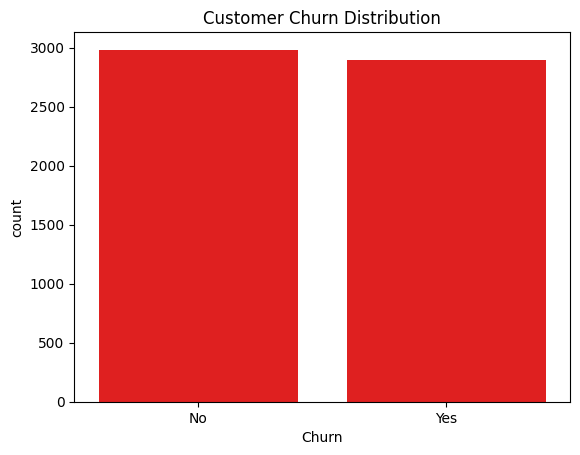

In [8]:
sns.countplot(data=df, x='Churn',color='red')

plt.title('Customer Churn Distribution')

plt.show()

In [9]:
df.drop('customerID', axis=1, inplace=True)

In [10]:
df.dtypes

,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [11]:
for col in df.columns:
    print(col, df[col].unique())

gender ['Male' 'Female']
SeniorCitizen [0 1]
Partner ['No' 'Yes']
Dependents ['Yes' 'No']
tenure [23 43 51 72 25 35 17 18 27 15 69 42 34 48  8 10  5 26 62 13  9 20 57 24
 33 60 64 30 14 19 71 59 67 44 32 11  2 68 40 46  4 38 63 29 70 52 55 66
 31 61 36 37 47 22 39 58  7 65  6 45  1 56 21 16 49 41  3 12 53 28 50 54]
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['No' 'DSL' 'Fiber optic']
OnlineSecurity ['No internet service' 'Yes' 'No']
OnlineBackup ['No internet service' 'No' 'Yes']
DeviceProtection ['No internet service' 'Yes' 'No']
TechSupport ['No internet service' 'No' 'Yes']
StreamingTV ['No internet service' 'Yes' 'No']
StreamingMovies ['No internet service' 'No' 'Yes']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Bank transfer' 'Mailed check' 'Electronic check' 'Credit card']
MonthlyCharges [ 49.85 100.7   97.33 ...  34.06  74.21  65.43]
TotalCharges [1146.55 4330.1  4963.83 ... 4065.04 

In [12]:
df['Churn'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

PAYMENT METHOD VS CHURN

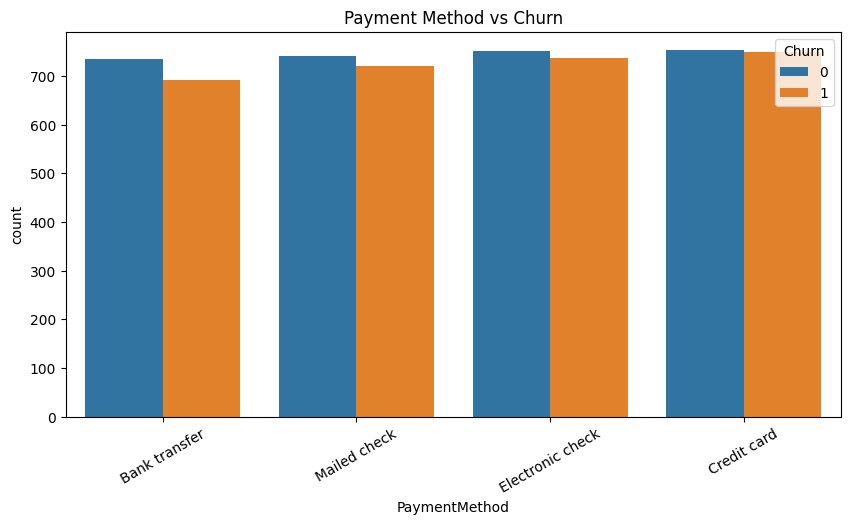

In [13]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn'
)

plt.xticks(rotation=30)

plt.title('Payment Method vs Churn')

plt.show()

MONTHLY CHARGES VS CHURN

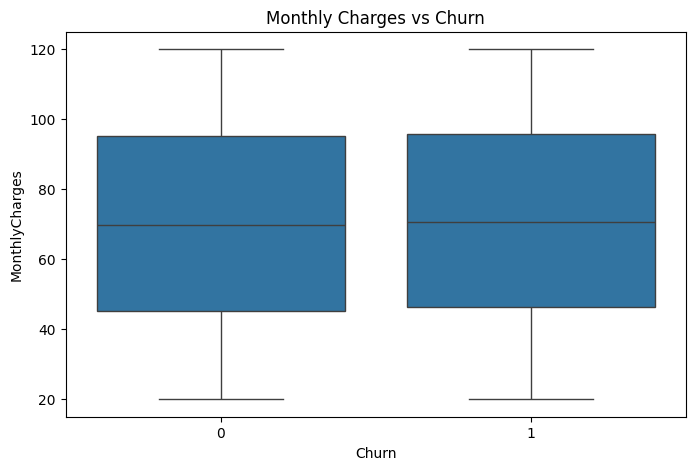

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Churn')

plt.show()

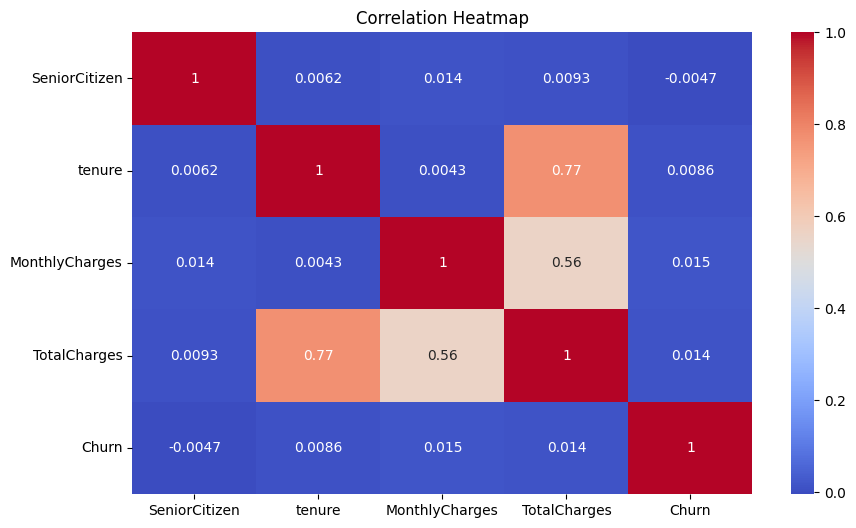

In [15]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

In [16]:
x = df.drop('Churn', axis=1)

y = df['Churn']

In [17]:
print(x.shape)

print(y.shape)

(5880, 19)
(5880,)


In [18]:
xtrain,xtest,ytrain,ytest = train_test_split(

    x,

    y,

    test_size=0.2,

    random_state=42,

    stratify=y

)

In [19]:
print(xtrain.shape)

print(xtest.shape)

(4704, 19)
(1176, 19)


ENCODING

In [20]:
numerical_columns = x.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_columns = x.select_dtypes(
    include=['object', 'category']
).columns

In [21]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [22]:
preprocessor = ColumnTransformer(

    transformers=[

        ('num', StandardScaler(), numerical_columns),

        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)

    ]

)

In [23]:
xtrain = preprocessor.fit_transform(xtrain)

xtest = preprocessor.transform(xtest)

In [24]:
feature_names = preprocessor.get_feature_names_out()

MODEL BUILDING

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from xgboost import XGBClassifier

In [26]:
models = {

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=100,
        random_state=42
    ),

    'XGBoost': XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42,
        eval_metric='logloss'
    )

}

In [28]:
results = []

trained_models = {}

for name, model in models.items():

    model.fit(xtrain,ytrain)

    ypred = model.predict(xtest)

    yprob = model.predict_proba(xtest)[:, 1]

    accuracy = accuracy_score(ytest,ypred)

    precision = precision_score(ytest,ypred)

    recall = recall_score(ytest,ypred)

    f1 = f1_score(ytest,ypred)

    roc = roc_auc_score(ytest,yprob)

    results.append({

        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC AUC': roc

    })

    trained_models[name] = model

    print('\nModel:', name)

    print(classification_report(ytest,ypred))


Model: Random Forest
              precision    recall  f1-score   support

           0       0.51      0.54      0.52       596
           1       0.50      0.47      0.49       580

    accuracy                           0.51      1176
   macro avg       0.50      0.50      0.50      1176
weighted avg       0.50      0.51      0.50      1176


Model: Extra Trees
              precision    recall  f1-score   support

           0       0.52      0.56      0.54       596
           1       0.51      0.47      0.49       580

    accuracy                           0.52      1176
   macro avg       0.51      0.51      0.51      1176
weighted avg       0.51      0.52      0.51      1176


Model: XGBoost
              precision    recall  f1-score   support

           0       0.49      0.48      0.49       596
           1       0.48      0.48      0.48       580

    accuracy                           0.48      1176
   macro avg       0.48      0.48      0.48      1176
weighted avg    

MODEL COMPARISON

In [29]:
results_df = pd.DataFrame(results)

print(results_df)

           Model  Accuracy  Precision    Recall  F1 Score   ROC AUC
0  Random Forest  0.505102   0.498188  0.474138  0.485866  0.500837
1    Extra Trees  0.515306   0.509259  0.474138  0.491071  0.517246
2        XGBoost  0.483844   0.477002  0.482759  0.479863  0.481555


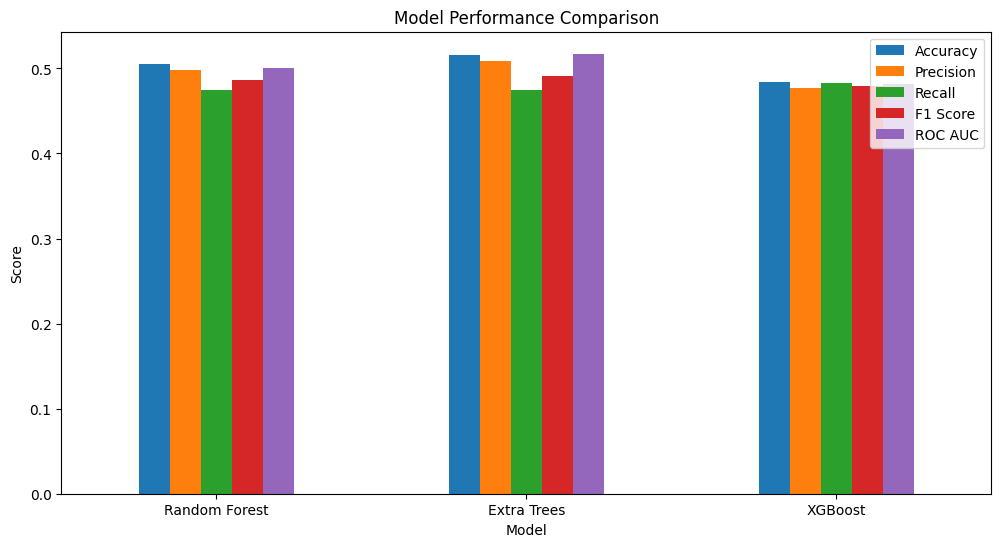

In [30]:
results_df.set_index('Model')[

    ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']

].plot(kind='bar', figsize=(12,6))

plt.title('Model Performance Comparison')

plt.ylabel('Score')

plt.xticks(rotation=0)

plt.show()

CONFUSION MATRIX

In [31]:
best_model_name = results_df.sort_values(
    by='F1 Score',
    ascending=False
).iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Extra Trees


In [33]:
ypred = best_model.predict(xtest)

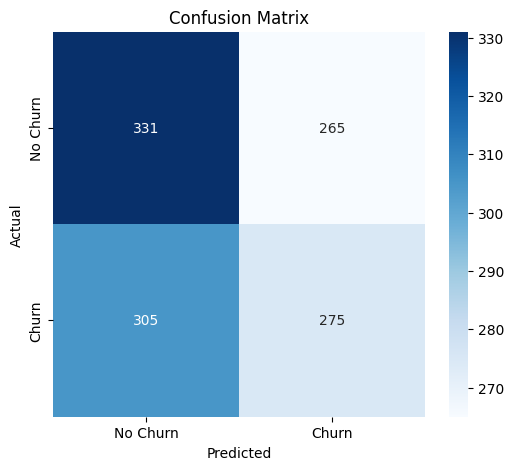

In [35]:
cm = confusion_matrix(ytest,ypred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted')

plt.ylabel('Actual')

plt.title('Confusion Matrix')

plt.show()

In [36]:
rf_model = trained_models['Random Forest']

In [37]:
importance = rf_model.feature_importances_

In [38]:
feature_importance = pd.DataFrame({

    'Feature': feature_names,

    'Importance': importance

})

In [39]:
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

In [40]:
print(feature_importance.head(15))

                                Feature  Importance
2                   num__MonthlyCharges    0.146661
3                     num__TotalCharges    0.145261
1                           num__tenure    0.134322
0                    num__SeniorCitizen    0.031673
44      cat__PaymentMethod_Mailed check    0.020495
37               cat__Contract_One year    0.020248
38               cat__Contract_Two year    0.019966
40            cat__PaperlessBilling_Yes    0.019862
42       cat__PaymentMethod_Credit card    0.019831
43  cat__PaymentMethod_Electronic check    0.019797
39             cat__PaperlessBilling_No    0.019641
9                   cat__Dependents_Yes    0.019596
8                    cat__Dependents_No    0.019593
36         cat__Contract_Month-to-month    0.019579
41     cat__PaymentMethod_Bank transfer    0.019316


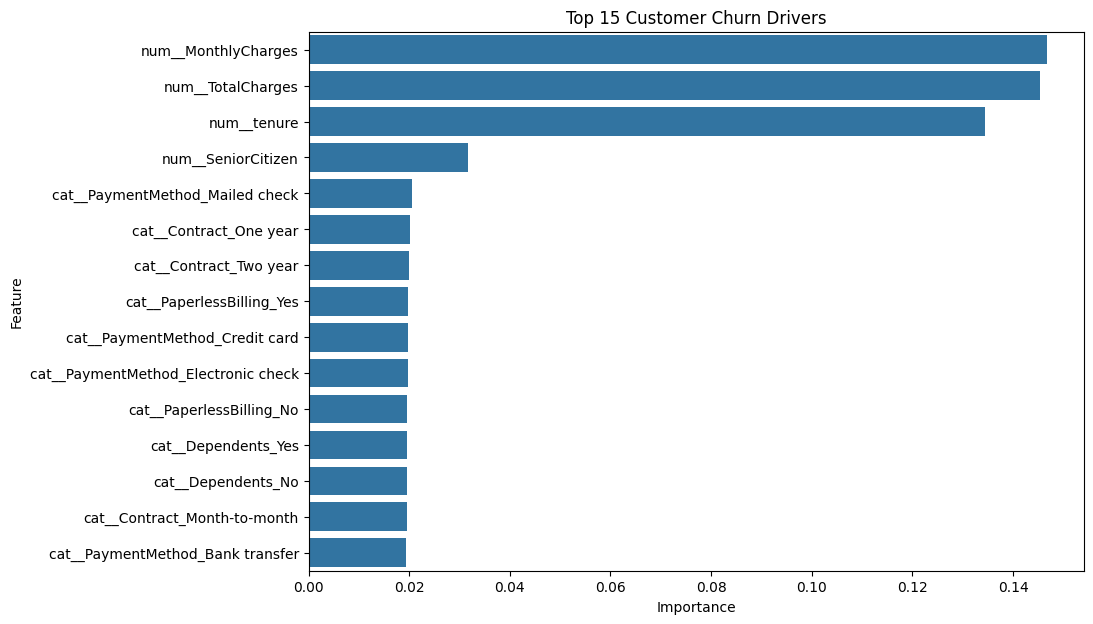

In [41]:
plt.figure(figsize=(10,7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Customer Churn Drivers')

plt.show()